In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml

In [3]:
fashion_mnist = fetch_openml("Fashion-MNIST", version=1, as_frame=True)
X = fashion_mnist.data #attributes (pixels)
y = fashion_mnist. target # Labels (classes)
print(X)
print(y)    

       pixel1  pixel2  pixel3  pixel4  pixel5  pixel6  pixel7  pixel8  pixel9  \
0           0       0       0       0       0       0       0       0       0   
1           0       0       0       0       0       1       0       0       0   
2           0       0       0       0       0       0       0       0       0   
3           0       0       0       0       0       0       0       0      33   
4           0       0       0       0       0       0       0       0       0   
...       ...     ...     ...     ...     ...     ...     ...     ...     ...   
69995       0       0       0       0       0       0       0       0       0   
69996       0       0       0       0       0       0       0       0       0   
69997       0       0       0       0       0       0       0       0       0   
69998       0       0       0       0       0       0       0       0       0   
69999       0       0       0       0       0       0       0       0       0   

       pixel10  ...  pixel7

In [4]:
print(fashion_mnist.data.min().min())
print(fashion_mnist.data.max().max())

0
255


In [5]:
class_names = {
    "0": "T-shirt/top",
    "1": "Trouser",
    "2": "Pullover",
    "3": "Dress",
    "4": "Coat",
    "5": "Sandal",
    "6": "Shirt",
    "7": "Sneaker",
    "8": "Bag",
    "9": "Ankle boot"
}


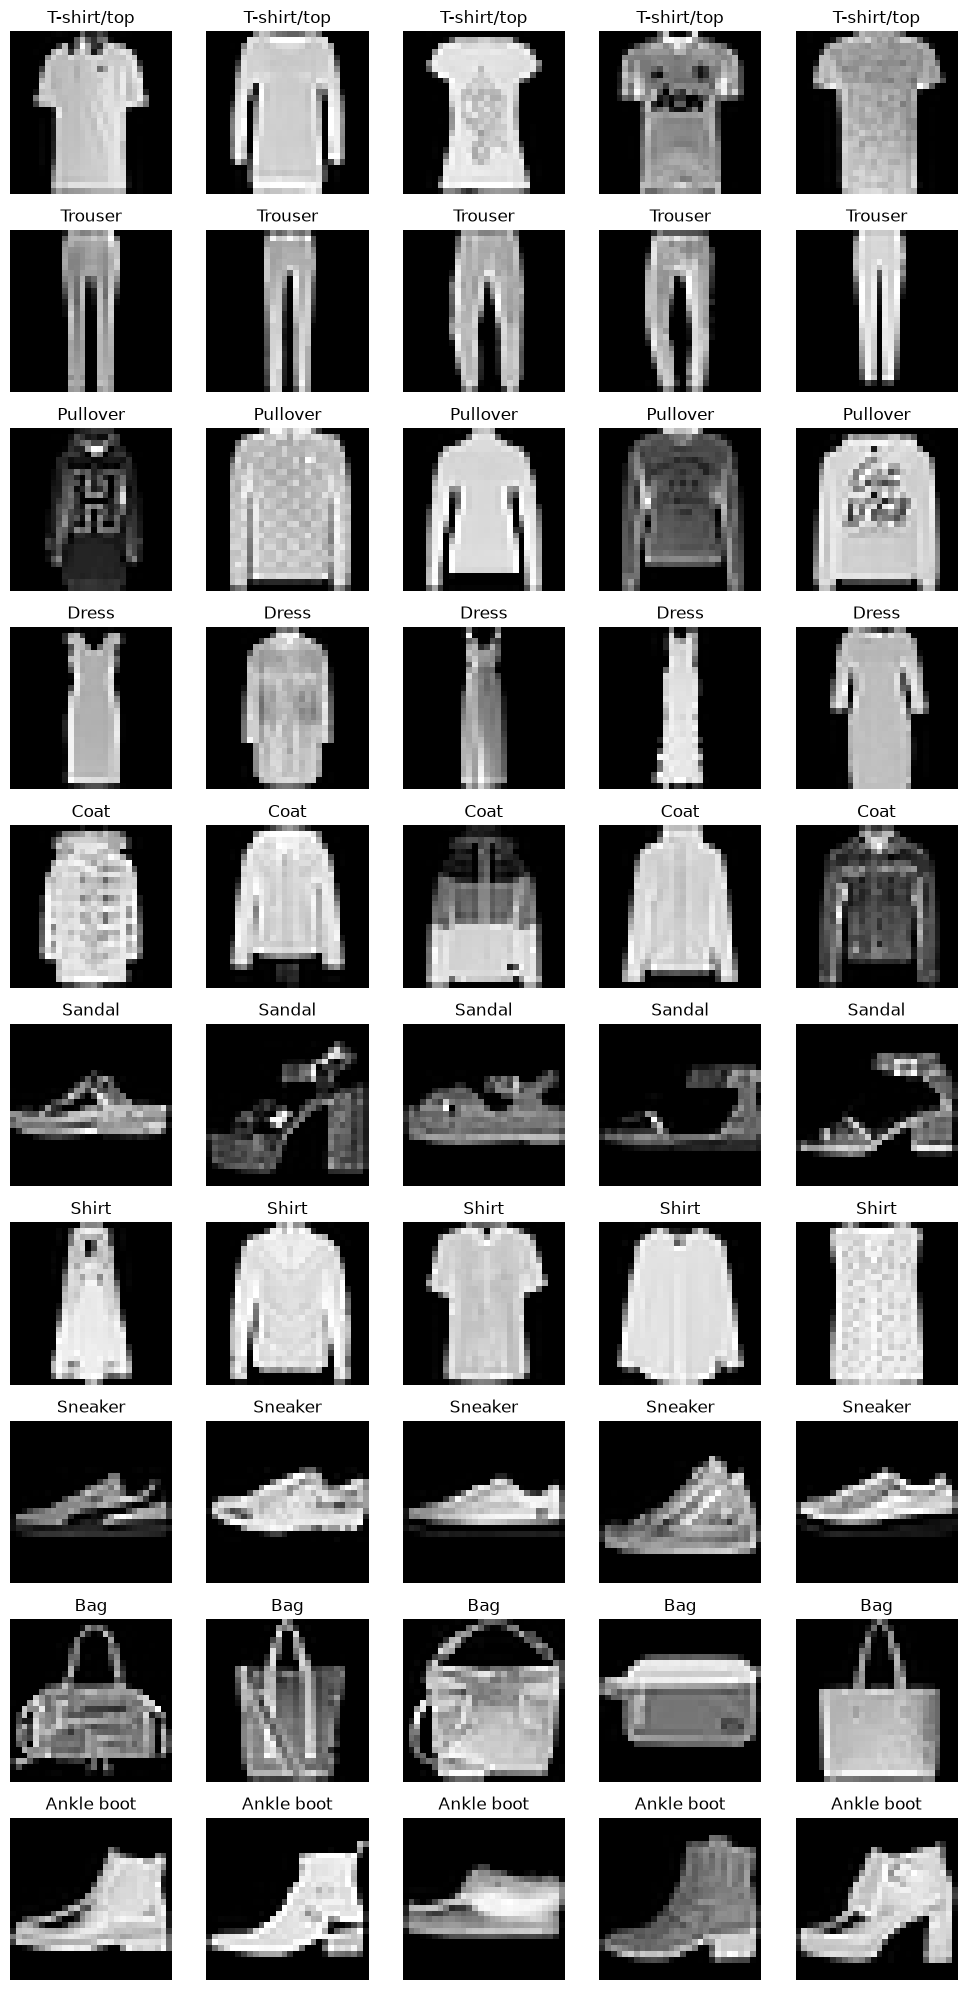

In [6]:
fig, axes = plt.subplots(10, 5, figsize=(10, 20))

for class_code in class_names:
    class_indices = np.where(y == class_code)[0]
    random_indices = np.random.choice(class_indices, 5, replace=False)

    row = int(class_code)

    for col, index in enumerate(random_indices):
        image = X.iloc[index].to_numpy().reshape(28, 28)

        axes[row, col].imshow(image, cmap="gray")
        axes[row, col].set_title(class_names[class_code])
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()

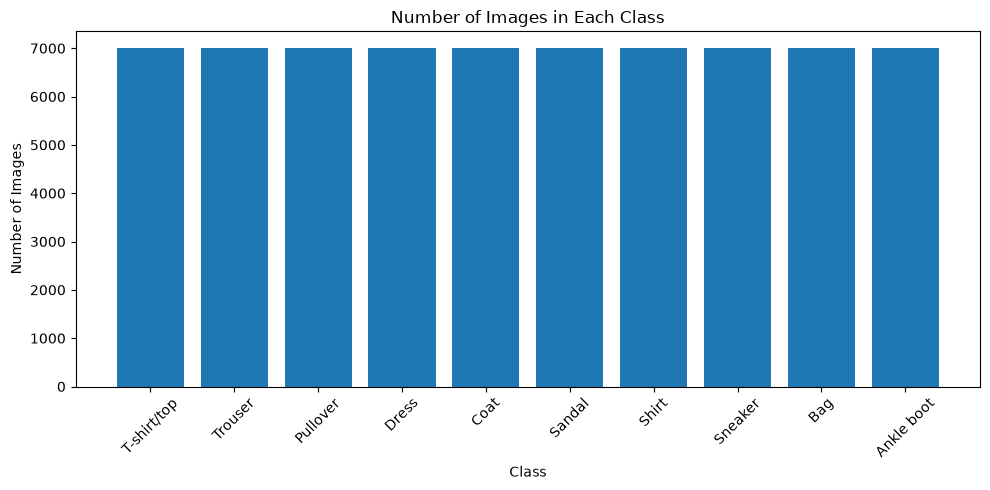

In [7]:
class_counts = y.value_counts().sort_index()

labels = [class_names[str(i)] for i in class_counts.index]

plt.figure(figsize=(10, 5))
plt.bar(labels, class_counts.values)

plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.title("Number of Images in Each Class")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
#The classes are evenly distributed, which means the dataset is well-balanced.

In [8]:
selected_indices = []

for class_code in class_names:
    class_indices = np.where(y == class_code)[0]
    random_indices = np.random.choice(class_indices, 100, replace=False)
    selected_indices.extend(random_indices)

selected_indices = np.array(selected_indices)

X_tsne = X.iloc[selected_indices].to_numpy()
y_tsne = y.iloc[selected_indices].to_numpy()

print("Number of selected samples:", len(selected_indices))
print("X shape:", X_tsne.shape)
print("y shape:", y_tsne.shape)

Number of selected samples: 1000
X shape: (1000, 784)
y shape: (1000,)


In [9]:
from sklearn.manifold import TSNE

tsne = TSNE(n_components=3, random_state=42)

X_tsne_3d = tsne.fit_transform(X_tsne)

print("Original shape:", X_tsne.shape)
print("t-SNE shape:", X_tsne_3d.shape)

Original shape: (1000, 784)
t-SNE shape: (1000, 3)


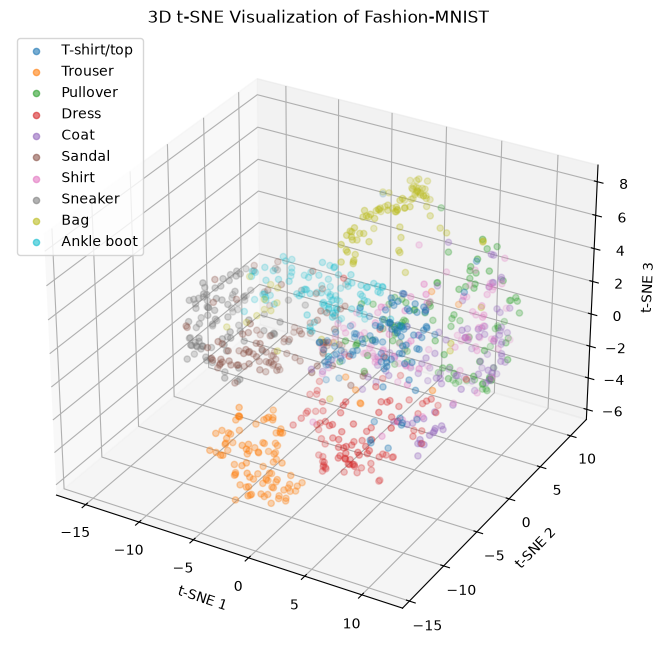

In [12]:
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection="3d")

for class_code in class_names:
    class_mask = y_tsne == class_code

    ax.scatter(
        X_tsne_3d[class_mask, 0],
        X_tsne_3d[class_mask, 1],
        X_tsne_3d[class_mask, 2],
        label=class_names[class_code],
        alpha=0.6
    )

ax.set_xlabel("t-SNE 1")
ax.set_ylabel("t-SNE 2")
ax.set_zlabel("t-SNE 3")
ax.set_title("3D t-SNE Visualization of Fashion-MNIST")
ax.legend()

plt.show()

#The 3D t-SNE visualization shows that some Fashion-MNIST classes form relatively
#distinct clusters, while other visually similar classes have more overlap.
#Therefore, the classes are not perfectly separable in the original feature space,
#although t-SNE makes several local class structures easier to visualize.